In [1]:
# finding and flagging contaminating (fake) barcodes in the in vivo barcoding data
# input: clustered barcode counts (metastatic-phenotypes/data/bc-counts-clustered/sample_clIDs_rBC_cluster_counts.txt) + metadata.csv
# output: a table of flagged sample-barcode pairs with the reason + updated reads (metastatic-phenotypes/data/bc-counts-cleaned/sample_clIDs_rBC_cluster_counts_cleaned.txt)

# five rules: spike-in contamination, too large at day 2, co-travelling barcodes (material from another sample),
# barcodes in too many day-2 mice, and 7160c2 left out of exp. 1 (library-prep contamination)
# note that another cell line was removed prior to this
# (the patterns made no sense and we later Sanger-sequenced the barcode and it shared it with another spike-in)
# as well as a mouse that was clearly a copy of another (and a few with very few total reads)

In [2]:
import os
import numpy as np
import pandas as pd
import scipy as sp
from scipy import stats
from scipy.optimize import brentq
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['pdf.fonttype'] = 42; matplotlib.rcParams['ps.fonttype'] = 42 # editable text
matplotlib.rcParams['axes.facecolor'] = 'none'; matplotlib.rcParams['figure.facecolor'] = 'white'
np.random.seed(0)

In [3]:
# parameters (sensitivity to each one is tested at the end)
# IN ALL CAPS SO THAT I KNOW

SPIKE_MIN_PRESENCE = 0.8 # rule 2: present in >= 80% of samples with spike-in
SPIKE_MIN_RATIO = 100    # rule 2: >= 100x rarer in samples without spike-in
SPIKE_MIN_CORR = 0.8     # rule 2: correlation with spike-in reads (log scale)
R_POOL = 5               # reads per DNA molecule in the pre-injection samples (no spike-in there; at most reads / barcodes seen, 4.6-7.6)
SPIKEIN_CELLS = {'1': 50000 / (1 + 0.69), '2': 50000} # spike-in (GATC) cells per sample: the exp. 1 stock also carried cells of other lines (0.69x the GATC reads, rule 2), counted in the 50,000
DAY2_G = 4               # rule 1: at most 4x growth by day 2 (two doublings)
ALPHA = 1e-4             # rule 1: test level
MIN_SHARED = 20          # rule 3: minimum number of barcodes two samples share to be tested
FOUND_MIN = 0.8          # rule 3, check 1: fraction of the source's expected clones found in the recipient
BELOW_MAX = 0.10         # rule 3, check 2: maximum fraction of shared barcodes clearly below the line
ALPHA_BELOW = 0.01       # rule 3, check 2: level for 'clearly below the line'
SPECIFIC_MIN = 3         # rule 3, check 3: found must be >= 3x the median found of the other sources into the recipient
KEEP_FOLD = 10           # rule 3: barcodes more than 10x above the line are the recipient's own (kept, and left out of the slope)
ALPHA_KEEP = 1e-4        # rule 3: level barcodes kept (above the line)
MANY_MICE_ALPHA = 1e-6   # rule 4: barcodes in more day-2 mice than the injection allows 

In [4]:
# where things are
path_to_data = '../data/'
path_to_reads = path_to_data + 'bc-counts-clustered/' # input: clustered counts
path_to_cleaned = path_to_data + 'bc-counts-cleaned/'; os.makedirs(path_to_cleaned, exist_ok=True)

path_to_save_figs = './figs/'; os.makedirs(path_to_save_figs, exist_ok=True)

metadata = pd.read_csv(path_to_data + 'metadata.csv', index_col='sample id') 

# cell line IDs & labels (same as figures/utils.py), spike-in first
clIDs = ['GATC', 'AAGG', 'ACAC', 'ACCT', 'ACGA', 'ACTG', 'AGAG', 'AGCA', 'AGGT', 'AGTC', 'ATCG', 'ATGC', 'CAAC', 'CACT', 'CAGA', 'CATG', 'CCAA', 'CCTT', 'CGAT', 'CGTA', 'CTGT', 'CTTC', 'GAAG', 'GCAT', 'GCTA', 'GGAA', 'GGTT', 'GTAC', 'GTGA', 'GTTG', 'TCCA', 'TGAC', 'TTCC', 'TTGG']
cell_line_labels = ['Spike-in 1', '7160c2', 'FC1199', '6694c2', '7160c5', 'BF857', 'BF1987', 'Panc02', '0688M', 'FC1245', 'BF4326', 'BF2117', '6419c5', 'BF4326Rep', 'KPC960', '0755P', 'BF1836', 'BF2014', 'BF5960', '6499c4', '6422c5', 'FC1245Rep', 'KPC-JH', 'KPC960Rep', 'BF2153', 'KC6141', 'mT3-2D', 'mT5-2D', '0764P', '6421c2', '0755A', '2838c3', 'FC1242', 'KPC961']
clID__label = dict(zip(clIDs, cell_line_labels))
clIDs_no_spikein = clIDs[1:]
clIDs_not_rejected = [x for x in clIDs_no_spikein if clID__label[x] not in ['KPC960', 'KPC960Rep', 'KPC961']]


# samples in scope: in vivo + pre-injection (day 0); no in vitro, no LA67 (iv pancreas, not used in any figure)
exp__pre_injection_samples = {e: list(metadata[(metadata['time point, d'] == 0) & (metadata['experiment'] == e)].index) for e in ['1', '2']}
pre_injection_samples = exp__pre_injection_samples['1'] + exp__pre_injection_samples['2']
samples = [s for s in metadata.index if metadata.loc[s, 'experiment'] != 'in vitro' and not s.startswith('LA67')]
in_vivo = [s for s in samples if s not in pre_injection_samples]

# mouse = eartag (all tissues & libraries from one mouse are one mouse); pre-injection samples are their own 'mouse'
sample__mouse = {s: (f'pre-injection{metadata.loc[s, "experiment"]}' if s in pre_injection_samples else str(metadata.loc[s, 'eartag (in vivo) / passage (in vitro)'])) for s in samples}
day2 = [s for s in in_vivo if metadata.loc[s, 'time point, d'] <= 3]
print(f'{len(samples)} samples ({len(in_vivo)} in vivo, {len(pre_injection_samples)} pre-injection), {len(set(sample__mouse[s] for s in in_vivo))} mice')

148 samples (144 in vivo, 4 pre-injection), 105 mice


In [5]:
# loading all barcode counts into one long table: sample, clID, barcode, reads
rows = []
for s in samples:
    df = pd.read_csv(path_to_reads + f'{s}_clIDs_rBC_cluster_counts.txt', sep='\t', header=None, names=['key', 'reads'])
    df['sample'] = s
    rows.append(df)
barcode_reads = pd.concat(rows, ignore_index=True)
barcode_reads['clID'] = barcode_reads.key.str[:4]; barcode_reads['barcode'] = barcode_reads.key.str[5:]
barcode_reads['exp'] = barcode_reads['sample'].map(metadata['experiment'])
barcode_reads['mouse'] = barcode_reads['sample'].map(sample__mouse)

# spike-in reads per sample, and frequency of each barcode within its sample (spike-in excluded)
sample__spikein_reads = barcode_reads[barcode_reads.clID == 'GATC'].groupby('sample').reads.sum().reindex(samples).fillna(0)
barcode_reads = barcode_reads[barcode_reads.clID != 'GATC'].copy()
barcode_reads['frac'] = barcode_reads.reads / barcode_reads.groupby('sample').reads.transform('sum')

print(f'{len(barcode_reads):,} sample-barcode pairs')

# barcode x sample tables of reads and frequencies
W_reads = barcode_reads.pivot_table(index='key', columns='sample', values='reads', aggfunc='sum').fillna(0)
W_frac = barcode_reads.pivot_table(index='key', columns='sample', values='frac', aggfunc='sum').fillna(0)

1,637,126 sample-barcode pairs


In [6]:
# the number of different spike-in barcodes we see gives how many of the N spike-in genomes made it into the PCR
# (N = SPIKEIN_CELLS: 50,000 in exp. 2, ~29,600 in exp. 1, where the 50,000 included cells of other lines - see below):
# templates of spike-in barcode b ~ Poisson(N * p_b * phi), where 
# p_b is the barcode's share of all spike-in reads, pooled over samples, and phi is the fraction of tissue that made it into PCR.
# phi is solved from the number of spike-in barcodes seen (>=2 reads);
# reads per template = spike-in reads / (N * phi); one template = 1/phi cells

In [7]:
spikein_samples = [s for s in in_vivo if metadata.loc[s, 'spike-in added']]
GATC = {} # spike-ins
for s in spikein_samples:
    df = pd.read_csv(path_to_reads + f'{s}_clIDs_rBC_cluster_counts.txt', sep='\t', header=None, names=['key', 'reads'])
    df = df[df.key.str.startswith('GATC')]
    GATC[s] = df.set_index('key').reads
GATC = pd.DataFrame(GATC).fillna(0)

# each spike-in barcode's share of all spike-in reads, pooled over samples (samples with few spike-in reads barely count)
p_b = GATC.sum(axis=1); p_b = p_b[p_b > 0] / p_b.sum()

calibration = {}
for s in spikein_samples:
    n_seen = int((GATC[s] >= 2).sum())
    N = SPIKEIN_CELLS[metadata.loc[s, 'experiment']] # spike-in cells in this sample
    phi = brentq(lambda f: np.sum(1 - np.exp(-N * p_b.values * f)) - n_seen, 1e-9, 10)
    calibration[s] = {'spikein_reads': int(GATC[s].sum()), 'spikein_bcs_seen': n_seen, 'phi': phi,
                      'cells_per_read': N / (1 + GATC[s].sum()), 'cells_per_template': 1 / phi,
                      'reads_per_template': GATC[s].sum() / (N * phi)}
calibration = pd.DataFrame(calibration).T
calibration['tissue'] = metadata.loc[calibration.index, 'tissue']; calibration['exp'] = metadata.loc[calibration.index, 'experiment']
calibration.groupby(['exp', 'tissue'])[['spikein_reads', 'cells_per_read', 'cells_per_template']].median().round(1)

spikein_reads  cells_per_read  cells_per_template
exp tissue                                                           
1   liver                 49818.0             0.6                44.7
    lung                  40076.0             0.7                13.5
    pancreas              18813.5             1.7                35.4
    peritoneal fat        41978.0             0.7                20.7
2   liver                   334.0           149.3              3566.1
    lung                   9238.0             5.4                32.5
    pancreas               3351.5            15.0                89.4

In [8]:
r_pool = R_POOL
# pools have no spike-in, so reads per molecule isn't measured and has to be guessed
# every barcode seen has >= 1 molecule, so it is at most reads / barcodes seen (4.6-7.6 across pools); 5 (above) is at the lower end
# any value from 2 to 10 removes 3.4-3.5% of in vivo reads in rule 1

key_exp__pre_injection_reads = {}; exp__pre_injection_total = {}
for e, ps in exp__pre_injection_samples.items():
    sub = barcode_reads[barcode_reads['sample'].isin(ps)]
    key_exp__pre_injection_reads[e] = sub.groupby('key').reads.sum(); exp__pre_injection_total[e] = sub.reads.sum()

def get_frac_0_upper(keys, e, r=r_pool, q=0.999):
    k = key_exp__pre_injection_reads[e].reindex(keys).fillna(0).values / r
    return sp.stats.gamma.ppf(q, k + 1) / (exp__pre_injection_total[e] / r)

barcode_reads['pre_injection_reads'] = 0.0; barcode_reads['frac_0_upper'] = np.nan
for e in exp__pre_injection_samples:
    m = barcode_reads.exp == e
    barcode_reads.loc[m, 'pre_injection_reads'] = key_exp__pre_injection_reads[e].reindex(barcode_reads.loc[m, 'key']).fillna(0).values
    barcode_reads.loc[m, 'frac_0_upper'] = get_frac_0_upper(barcode_reads.loc[m, 'key'], e)

In [9]:
# first, barcodes that came with the spike-in (rule 2 above) – noticed them after staring at the plots for way too long

# def. barcode as spike-in-borne (in a given experiment) if it is
# 1. present in ≥ 80% of samples with spike-in;
# 2. ≥ 100× rarer in samples without spike-in
# (the pre-injectin pools; a few stray reads there are allowed, since they were sequenced together with spike-in samples);
# 3. its reads go up and down with the spike-in reads (correlation of log reads >= 0.8)


In [10]:
def spikein_borne(e, min_pres=SPIKE_MIN_PRESENCE, min_ratio=SPIKE_MIN_RATIO, min_corr=SPIKE_MIN_CORR):
    ss = [s for s in samples if metadata.loc[s, 'experiment'] == e] # all samples from exp
    S = [s for s in ss if metadata.loc[s, 'spike-in added']]; N = [s for s in ss if not metadata.loc[s, 'spike-in added']] # with and wothout spike-in
    R = W_reads.reindex(columns=ss).fillna(0) # reads from exp
    cand = R.index[(R[S] > 0).mean(axis=1) >= min_pres] # candidate barcodes on rule 1
    out = []
    for k in cand:
        corr = np.corrcoef(np.log10(R.loc[k, S] + 1), np.log10(sample__spikein_reads[S] + 1))[0, 1]
        F_with = W_frac.loc[k, S].median(); F_without = W_frac.loc[k, N].mean() if N else 0
        if F_with >= min_ratio * F_without and corr >= min_corr:
            out.append({'key': k, 'exp': e, 'corr_with_spikein': corr, 'reads_per_spikein_read': (R.loc[k, S] / sample__spikein_reads[S]).median()})
    return pd.DataFrame(out)

spike_borne = pd.concat([spikein_borne('1'), spikein_borne('2')], ignore_index=True);
print(f'{len(spike_borne)} spike-in-borne barcodes:', spike_borne.groupby('exp').size().to_dict())
print(f"together they have {spike_borne.reads_per_spikein_read.sum():.2f}x the spike-in reads")
spike_borne.round(3)

13 spike-in-borne barcodes: {'1': 13}
together they have 0.69x the spike-in reads


,key,exp,corr_with_spikein,reads_per_spikein_read
0,CATG_AGGGTGTGTAGGTGTG,1,0.964,0.089
1,CATG_CCAGTGAGGTCGCCCG,1,0.961,0.052
2,CATG_TCGGTTCGTGGGAGGG,1,0.857,0.004
3,CATG_TGAGGTGGTGGGCGTG,1,0.968,0.087
4,GTTG_AAGGAACGGCTGCTAG,1,0.953,0.035
5,GTTG_CAAGCTAGACTGCAGG,1,0.958,0.038
6,GTTG_CCCGATGGTTTGATGG,1,0.960,0.065
7,GTTG_GAAGTGTGCATGCCCG,1,0.958,0.058
8,GTTG_GATGATGGGTGGTAGG,1,0.964,0.081
9,GTTG_GTTGAGGGCTGGAGGG,1,0.958,0.048


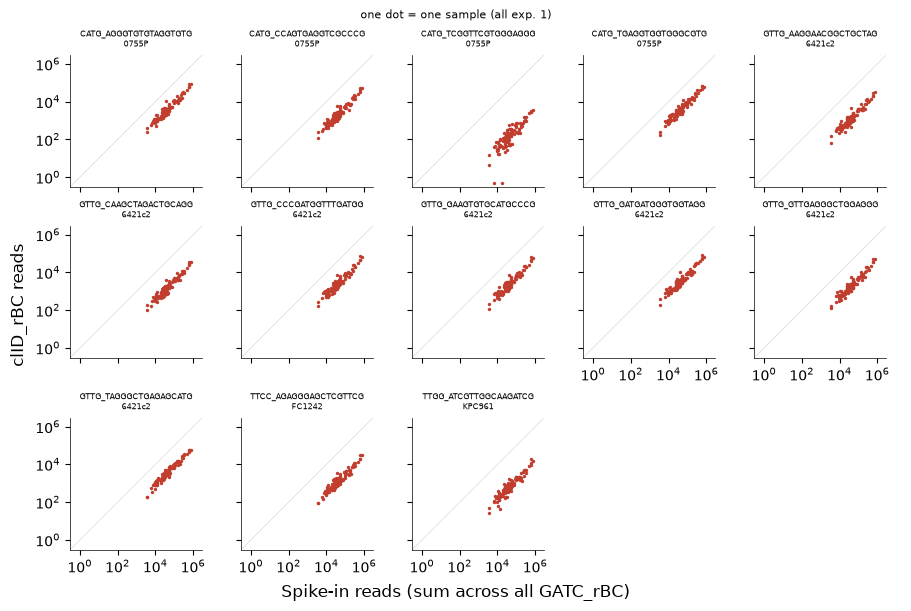

In [11]:
name = 'spikein_borne_barcodes'
si = 'si'

ss1 = [s for s in in_vivo if metadata.loc[s, 'experiment'] == '1' and metadata.loc[s, 'spike-in added']] # samples
keys = list(spike_borne.key)

fig, axes = plt.subplots(3, 5, figsize=(9, 6), sharex=True, sharey=True, layout='constrained')
for ax, k in zip(axes.flat, keys):
    ax.spines[['top', 'right']].set_visible(False); ax.spines[['bottom', 'left']].set_linewidth(0.5)
    ax.scatter(sample__spikein_reads[ss1], W_reads.loc[k, ss1] + 0.5, s=6, color='#c13e2e', alpha=1, linewidth=0)
    ax.plot([1e-2, 1e7], [1e-2, 1e7], color='#d9d9d9', linewidth=0.5)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.minorticks_off()
    ax.set_xticks([1e0, 1e2, 1e4, 1e6]); ax.set_yticks([1e0, 1e2, 1e4, 1e6])
    ax.set_box_aspect(1) 
    ax.set_title(k + '\n' + clID__label[k[:4]], size=6)
    
for i in range(len(keys), axes.size):
    axes.flat[i].axis('off'); axes.flat[i - 5].tick_params(labelbottom=True) # show x ticks on the panel above an empty one
    
axes[0, 0].set_xlim(3e-1, 3e6); axes[0, 0].set_ylim(3e-1, 3e6)

fig.supxlabel('Spike-in reads (sum across all GATC_rBC)', size=12); fig.supylabel('clID_rBC reads', size=12)
fig.suptitle('one dot = one sample (all exp. 1)', size=8)
plt.savefig(path_to_save_figs + si + '_' + name + '.pdf', dpi=300, bbox_inches='tight'); plt.show()

In [12]:
# NOTE: this suggests that spike-in normalization is incorrect as is – if these cells came with the spike-in, and were counted as spike in, we need to remove them

In [13]:
barcode_reads['SPIKE'] = barcode_reads.set_index(['exp', 'key']).index.isin(list(zip(spike_borne.exp, spike_borne.key))) & ~barcode_reads['sample'].isin(pre_injection_samples)

In [14]:
# now, day-2 clones bigger than a few doublings allow

# at 2 days, clone b in sample s can have at most N_injected × f_b × G cells (f_b = upper bound on pool frequency, growth G = 4, i.e. two doublings)
# in templates (using the spike-in calibration): expected <= N × f_b × G × phi_s, observed = reads / reads-per-template
# flag if P(Poisson(expected) ≥ observed) < 1e-4 (this is ALPHA)

In [15]:
def day2_flags(G_max=DAY2_G, alpha=ALPHA):
    out = []
    for s in day2:
        sub = barcode_reads[barcode_reads['sample'] == s]
        lam = metadata.loc[s, 'initial number of cells'] * sub.frac_0_upper.values * G_max * calibration.loc[s, 'phi']
        obs = np.floor(sub.reads.values / calibration.loc[s, 'reads_per_template'])
        p = sp.stats.poisson.sf(obs - 1, lam)
        out.append(pd.DataFrame({'index': sub.index, 'p': p, 'cells': sub.reads.values * calibration.loc[s, 'cells_per_read'], 'cells_max': lam / calibration.loc[s, 'phi']}))
    out = pd.concat(out).set_index('index')
    return out, out.index[out.p < alpha]

day2_table, day2_idx = day2_flags()
barcode_reads['DAY2'] = barcode_reads.index.isin(day2_idx)
print(f'{len(day2_idx)} day-2 sample-barcode pairs flagged')
barcode_reads[barcode_reads.DAY2].groupby('sample').reads.sum().div(barcode_reads[barcode_reads['sample'].isin(day2)].groupby('sample').reads.sum()).fillna(0).sort_values(ascending=False).round(2).to_frame('flagged read fraction').T;

704 day-2 sample-barcode pairs flagged


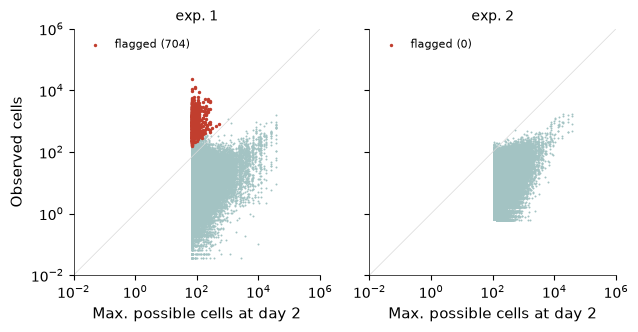

In [16]:
name = 'day2_upper_bound'
si = 'si'

fig, axes = plt.subplots(1, 2, figsize=(7, 3.2), sharey=True)
for ax, e in zip(axes, ['1', '2']):
    ss = [s for s in day2 if metadata.loc[s, 'experiment'] == e]
    t = day2_table.loc[barcode_reads.index[barcode_reads['sample'].isin(ss)].intersection(day2_table.index)]
    fl = t.p < 1e-4 # flagged
    
    ax.scatter(t.cells_max[~fl], t.cells[~fl], s=2, color='#a3c3c3', linewidth=0, rasterized=True)
    ax.scatter(t.cells_max[fl], t.cells[fl], s=6, color='#c13e2e', linewidth=0, label=f'flagged ({fl.sum()})')
    
    ax.plot([1e-2, 1e6], [1e-2, 1e6], color='#d9d9d9', linewidth=0.5)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.minorticks_off(); ax.legend(frameon=False, fontsize=8)
    ax.set_xlim(1e-2, 1e6); ax.set_ylim(1e-2, 1e6)
    
    ax.spines[['top', 'right']].set_visible(False); ax.spines[['bottom', 'left']].set_linewidth(0.5)
    ax.set_xlabel('Max. possible cells at day 2', size=11); ax.set_title(f'exp. {e}', size=10)
axes[0].set_ylabel('Observed cells', size=11)
plt.savefig(path_to_save_figs + si + '_' + name + '.pdf', dpi=300, bbox_inches='tight'); plt.show()

In [17]:
# where do the day-2 flagged barcodes come from?
# home = the 3-week sample of another mouse, same experiment, where the barcode is most frequent
late = [s for s in in_vivo if metadata.loc[s, 'time point, d'] > 3]
fl = barcode_reads[barcode_reads.DAY2]
rows = []
for _, r in fl.iterrows():
    cand = [s for s in late if metadata.loc[s, 'experiment'] == r.exp and sample__mouse[s] != r.mouse]
    w = W_frac.loc[r.key, cand]
    rows.append({'home': w.idxmax() if w.max() > 0 else 'none', 'home_frac': w.max(), 'n_carrying': int((w > 0).sum())})
home = pd.concat([fl[['sample', 'clID', 'key', 'reads', 'SPIKE']].reset_index(drop=True), pd.DataFrame(rows)], axis=1)
home['cell line'] = home.clID.map(clID__label)
home['why'] = np.select([home.SPIKE, home.home == 'none'], ['spike-in barcode', 'no home'], 'has a home')

print(home[home.why == 'has a home'].home.value_counts().head(5).to_string(), '\n')
print(home[home.why == 'no home']['cell line'].value_counts().to_string())

home
SK1_14    189
SK1_18    146
SK1_16      3
SK1_21      2
SK1_44      1 

cell line
7160c2    134


In [18]:
# NOTE: the above suggests that 7160c2 contaminated stuff at the level of library prep

In [19]:
# ok, now the hardest with the most tweaks: samples that contain material from another sample (co-travelling barcodes)

# if sample s leaked into sample r, r holds all of s's clones at one fixed fraction (the dose), biggest clones first
# every ordered pair s -> r (different mice, >= 20 shared barcodes (MIN_SHARED); across experiments too, since exp. 1 material could reach exp. 2 samples through reagents) is tested
# each library is tested on its own (contamination can enter one library not the other even when samples are from the same mouse/tissue)
# the spike-in barcodes from above are left out since they're taken care of

# slope (dose) = median of f_r / f_s over shared barcodes, recalculated once again without the barcodes more than 10× above that first line 
# (the recipient's own tumors can only sit above the line; they would pull it up) - black line in the plots below (or THE LINE)

# 1. at a given dose, each clone of s is expected in r with probability 1 − exp(−slope × f_s × M_r) (M_r = molecules in r)
# found = clones present / clones expected; pass if >= 0.8 (FOUND_MIN)

# 2. contamination only adds, so r should have at least slope * s's amount of each shared barcode
# a barcode is clearly below the line if P(Binomial(n, q) <= m_r) < 0.01 (ALPHA_BELOW = 0.01), 
# with n = m_s + m_r molecules and q the share of them the line puts in r
# pass if < 10% of shared barcodes are clearly below (BELOW_MAX)

# 3. the source must stand out: a recipient that carries most common pool barcodes (e.g. a day-2 lung) shares clones with every source
# pass if found for s -> r is >= 3x the median found of all other sources from s's experiment tested into r (SPECIFIC_MIN = 3)

# multiple sources: if s is an accepted recipient of t, its barcodes fall on two lines in r: what s got from t, and s's own clones
# so s -> r is tested again on s's own clones only (s's barcodes not in t)
# what s got from t is removed from r through t -> r

# REMOVE from r every barcode shared with an accepted source UNLESS it is clearly above that source's line (P(Binomial(n, q) ≥>+ m_r) < 1e-4) or more than 10× above it
# (small barcodes, ~1 molecule, can never be clearly above; 10× above the line can't be this source's contamination) - controlled by KEEP_FOLD and ALPHA_KEEP

# sanity checks: all pairs were looked at by eye and parameters were chosen so that the clouds separate; sensitivity tests performed below;
# pairs with an exp. 2 source and an exp. 1 recipient can't be contamination (exp. 2 was sequenced months later): they are tested but never removed, as a check


In [20]:
keys = W_reads.index[~W_reads.index.isin(set(spike_borne.key))]

# per library: which barcodes it has, their frequencies and their molecule counts
lib = {}
for s in in_vivo:
    reads = W_reads.loc[keys, s].values 
    mol = reads / calibration.loc[s, 'reads_per_template'] # molecules, from the spike-in calibration
    nz = np.flatnonzero(reads > 0) # positions (in keys) of the barcodes present
    lib[s] = {'idx': nz, 'frac': reads[nz] / reads.sum(), 'm': mol[nz], 'M': mol.sum(), 
              'reads': reads, 'exp': metadata.loc[s, 'experiment'], 'mouse': sample__mouse[s]}

def pair_stats(s, r, excl=None, min_shared=5): 
    # could source s have leaked into recipient r?
    # excl = barcodes to leave out of s 
    a, b = lib[s], lib[r]
    keep = np.ones(len(a['idx']), bool) if excl is None else ~np.isin(a['idx'], excl)
    idx, frac, m = a['idx'][keep], a['frac'][keep], a['m'][keep] # s's barcodes, frequencies, molecules
    common, ia, ib = np.intersect1d(idx, b['idx'], return_indices=True) # barcodes in both; ia, ib = their positions in s and r
    if len(common) < min_shared: return None

    # slope: how much of s ended up in r = median of f_r / f_s over the shared barcodes
    # refit once without barcodes > 10x above the line (r's own tumors)
    ratio = b['frac'][ib] / frac[ia]; slope = np.median(ratio)
    slope = np.median(ratio[ratio <= KEEP_FOLD * slope])                          

    # check 1: number of s's clones expected in r at this dose (each one seen with prob. 1 - exp(-slope * f_s * M_r))
    expected = np.sum(1 - np.exp(-slope * frac * b['M']))

    # per-barcode test against the line, on molecules: the line puts a share q in r
    # x = molecules actually in r
    k = slope * b['M'] / a['M']; q = k / (1 + k)
    n = np.round(m[ia] + b['m'][ib]).astype(int) # barcode molecules in s and r together
    x = np.round(b['m'][ib]).astype(int) # barcode molecules in r
    ok = n >= 1 # barcodes with < 1 molecule can't be tested
    p_low = np.full(len(common), np.nan); p_high = np.full(len(common), np.nan)
    p_low[ok] = sp.stats.binom.cdf(x[ok], n[ok], q) # small = clearly below the line (check 2)
    p_high[ok] = sp.stats.binom.sf(x[ok] - 1, n[ok], q) # small = clearly above the line (kept: r's own tumor)

    return {'source': s, 'recipient': r, 'exp_s': a['exp'], 'exp_r': b['exp'], 'shared': len(common), 'slope': slope,
            'found': len(common) / expected, 'common': common, 'fs': frac[ia], 'fr': b['frac'][ib], 'p_low': p_low, 'p_high': p_high}

# test every ordered pair of libraries from different mice (same mouse: can't tell contamination from shared tumors)
all_pairs = []
for s in lib:
    for r in lib:
        if s == r or lib[s]['mouse'] == lib[r]['mouse']: continue
        st = pair_stats(s, r)
        if st: all_pairs.append(st)
print(len(all_pairs), 'pairs tested')

17826 pairs tested


In [21]:
def decide(pairs, found_min=FOUND_MIN, below_max=BELOW_MAX, alpha_bc=ALPHA_BELOW, specific_min=SPECIFIC_MIN):
    # one row per tested pair s -> r, with the three checks
    rows = []
    for p in pairs:
        pl = p['p_low'][~np.isnan(p['p_low'])] # 'below the line' p-values of the testable shared barcodes
        below = (pl < alpha_bc).mean() if len(pl) else 0.0 # share of them clearly below the line
        rows.append({'source': p['source'], 'recipient': p['recipient'], 'exp_s': p['exp_s'], 'exp_r': p['exp_r'],
                     'shared': p['shared'], 'slope': p['slope'], 'found': p['found'], 'below': below,
                     'check_1': p['found'] >= found_min, # check 1: the source's clones are there
                     'check_2': below < below_max}) # check 2: (almost) nothing clearly below the line
    T = pd.DataFrame(rows)
    T['impossible'] = (T.exp_s == '2') & (T.exp_r == '1') # exp. 2 was sequenced months after exp. 1: tested as a check, never removed

    # check 3: the source stands out = found(s -> r) / median found of all other sources (same experiment as s) into r
    T['found_others'] = np.nan
    for _, g in T.groupby(['recipient', 'exp_s']):
        v = g.found.values
        T.loc[g.index, 'found_others'] = [np.median(np.delete(v, i)) if len(v) > 1 else np.nan for i in range(len(v))] # median without s itself
    T['specific'] = T.found / T.found_others # check 3 score
    T['check_3'] = ~(T.specific < specific_min) # NaN (r has no other source to compare with) passes
    T['accepted'] = T.check_1 & T.check_2 & T.check_3
    return T

def resolve(pairs, min_shared=MIN_SHARED, **kw):
    # first pass: every pair, on all of the source's barcodes
    T1 = decide(pairs, **kw)
    sources_of = T1[T1.accepted & ~T1.impossible].groupby('recipient').source.apply(list).to_dict() # recipient -> its accepted sources

    # second pass: a source that is itself contaminated is tested again on its own tumors only
    out = []
    for p in pairs:
        s, r = p['source'], p['recipient']
        ts = [t for t in sources_of.get(s, []) if t != r] # s's own sources (if r leaked into s, leaving out r's barcodes would leave nothing to test)
        if ts:
            q = pair_stats(s, r, excl=np.unique(np.concatenate([lib[t]['idx'] for t in ts])), min_shared=min_shared)
            if q is None: continue # too few shared barcodes left
            q['own_only'] = True
        else:
            q = dict(p, own_only=False)
        out.append(q)
    T = decide(out, **kw); T['own_only'] = [q['own_only'] for q in out]
    first = T1.set_index(['source', 'recipient']).accepted
    T['accepted_on_all_barcodes'] = first.reindex(list(zip(T.source, T.recipient))).values # first-pass result, for comparison
    return T, {(q['source'], q['recipient']): q for q in out} # pair table + per-pair stats (used to flag barcodes)

def explained(p, alpha_keep=ALPHA_KEEP, keep_fold=KEEP_FOLD):
    # which shared barcodes the source explains: all, unless clearly above the line or more than keep_fold x above it (r's own tumors)
    return ~((p['p_high'] < alpha_keep) | (p['fr'] / p['fs'] / p['slope'] > keep_fold))

sample__rows = barcode_reads.groupby('sample').indices # sample -> its row positions in barcode_reads
def cotravel_flags(T, P, alpha_keep=ALPHA_KEEP, keep_fold=KEEP_FOLD):
    # barcodes each recipient loses, and from which source(s); a barcode explained by several sources is removed once
    removed = {} # recipient -> {barcode key: [sources]}
    for s, r in T.loc[T.accepted & ~T.impossible, ['source', 'recipient']].values:
        p = P[(s, r)]
        for k in p['common'][explained(p, alpha_keep, keep_fold)]:
            removed.setdefault(r, {}).setdefault(keys[k], []).append(s)

    # mark those rows in barcode_reads
    flagged = np.zeros(len(barcode_reads), bool); src = np.full(len(barcode_reads), '', dtype=object)
    for r, key__sources in removed.items():
        rows = sample__rows[r]; hit = barcode_reads['key'].values[rows]
        m = pd.Series(hit).isin(list(key__sources)).values
        flagged[rows[m]] = True; src[rows[m]] = [';'.join(sorted(key__sources[h])) for h in hit[m]]
    return pd.Series(flagged, index=barcode_reads.index), pd.Series(src, index=barcode_reads.index)

# run: pairs sharing >= MIN_SHARED barcodes
cotravel, pair__stats = resolve([p for p in all_pairs if p['shared'] >= MIN_SHARED])
barcode_reads['COTRAVEL'], barcode_reads['cotravel_source'] = cotravel_flags(cotravel, pair__stats)

acc = cotravel[cotravel.accepted & ~cotravel.impossible]
print(f'{len(acc)} accepted pairs ({acc.source.nunique()} sources, {acc.recipient.nunique()} recipients), {int(acc.own_only.sum())} of them with a contaminated source, tested on the source\'s own tumors only')
print(f'exp. 1 -> exp. 2 accepted: {int(((acc.exp_s == "1") & (acc.exp_r == "2")).sum())}; impossible pairs accepted: {int(cotravel[cotravel.impossible].accepted.sum())} of {int(cotravel.impossible.sum())}')
print(f'{int(barcode_reads.COTRAVEL.sum())} sample-barcode pairs flagged')
print('\n e.g. below (20 pairs)')
acc.sort_values('slope', ascending=False).round(3).head(20)

165 accepted pairs (22 sources, 52 recipients), 70 of them with a contaminated source, tested on the source's own tumors only
exp. 1 -> exp. 2 accepted: 0; impossible pairs accepted: 0 of 2251
10566 sample-barcode pairs flagged

 e.g. below (20 pairs)


,source,recipient,exp_s,exp_r,shared,slope,found,below,check_1,check_2,impossible,found_others,specific,check_3,accepted,own_only,accepted_on_all_barcodes
3388,SK1_14,SK1_49,1,1,391,0.887,0.948,0.036,True,True,False,0.048,19.603,True,True,False,True
3389,SK1_14,SK1_50,1,1,197,0.292,0.950,0.010,True,True,False,0.025,37.616,True,True,False,True
3529,SK1_18,SK1_58_2,1,1,252,0.289,1.093,0.016,True,True,False,0.196,5.570,True,True,False,True
3528,SK1_18,SK1_58,1,1,260,0.244,1.129,0.004,True,True,False,0.219,5.159,True,True,False,True
3402,SK1_14,SK1_37,1,1,367,0.200,0.921,0.054,True,True,False,0.010,91.117,True,True,False,True
3386,SK1_14,SK1_47,1,1,171,0.153,0.896,0.006,True,True,False,0.048,18.755,True,True,False,True
3468,SK1_16,SK1_48,1,1,161,0.145,1.093,0.031,True,True,False,0.090,12.147,True,True,True,True
3384,SK1_14,SK1_45,1,1,233,0.126,1.023,0.004,True,True,False,0.104,9.800,True,True,False,True
3376,SK1_14,SK1_56,1,1,216,0.085,1.053,0.009,True,True,False,0.102,10.287,True,True,False,True
3467,SK1_16,SK1_47,1,1,101,0.069,0.993,0.000,True,True,False,0.048,20.787,True,True,True,True


In [22]:
# accepted pairs by condition: experiment, time point, genotype, injection route, tissue
short = {'intravenous': 'i.v.', 'intraperitoneal': 'i.p.', 'intrapancreatic': 'i.panc.', 'intrasplenic': 'i.spl.', 'C57B6/129S F1': 'F1', 'Rag1-/-': 'Rag1-/-'}
def condition(s):
    md = metadata.loc[s]
    t = 'day 2' if md['time point, d'] <= 3 else '3 wk'
    return f"exp. {md['experiment']}, {t}, {short[md['genotype']]}, {short[md['injection method']]} {md['tissue']}"

acc = cotravel[cotravel.accepted & ~cotravel.impossible].copy()
acc['source condition'] = acc.source.map(condition); acc['recipient condition'] = acc.recipient.map(condition)
acc.groupby(['source condition', 'recipient condition']).agg(pairs=('source', 'size'), sources=('source', 'nunique'), recipients=('recipient', 'nunique')).sort_values('pairs', ascending=False).reset_index()

,source condition,recipient condition,pairs,sources,recipients
0,"exp. 1, 3 wk, Rag1-/-, i.v. lung","exp. 1, 3 wk, F1, i.v. lung",54,8,22
1,"exp. 1, 3 wk, Rag1-/-, i.v. lung","exp. 1, day 2, F1, i.v. lung",38,5,13
2,"exp. 1, 3 wk, Rag1-/-, i.v. lung","exp. 1, day 2, Rag1-/-, i.v. lung",17,5,6
3,"exp. 1, 3 wk, F1, i.v. lung","exp. 1, 3 wk, F1, i.p. peritoneal fat",15,10,4
4,"exp. 1, 3 wk, F1, i.v. lung","exp. 1, 3 wk, F1, i.p. liver",13,8,2
5,"exp. 1, 3 wk, F1, i.v. lung","exp. 1, 3 wk, F1, i.p. pancreas",8,6,2
6,"exp. 1, 3 wk, Rag1-/-, i.v. lung","exp. 1, 3 wk, F1, i.p. liver",6,4,3
7,"exp. 1, 3 wk, F1, i.v. lung","exp. 1, 3 wk, F1, i.v. lung",5,4,2
8,"exp. 1, 3 wk, F1, i.p. peritoneal fat","exp. 1, 3 wk, F1, i.p. pancreas",4,2,2
9,"exp. 1, 3 wk, F1, i.p. peritoneal fat","exp. 1, 3 wk, F1, i.p. peritoneal fat",2,2,1


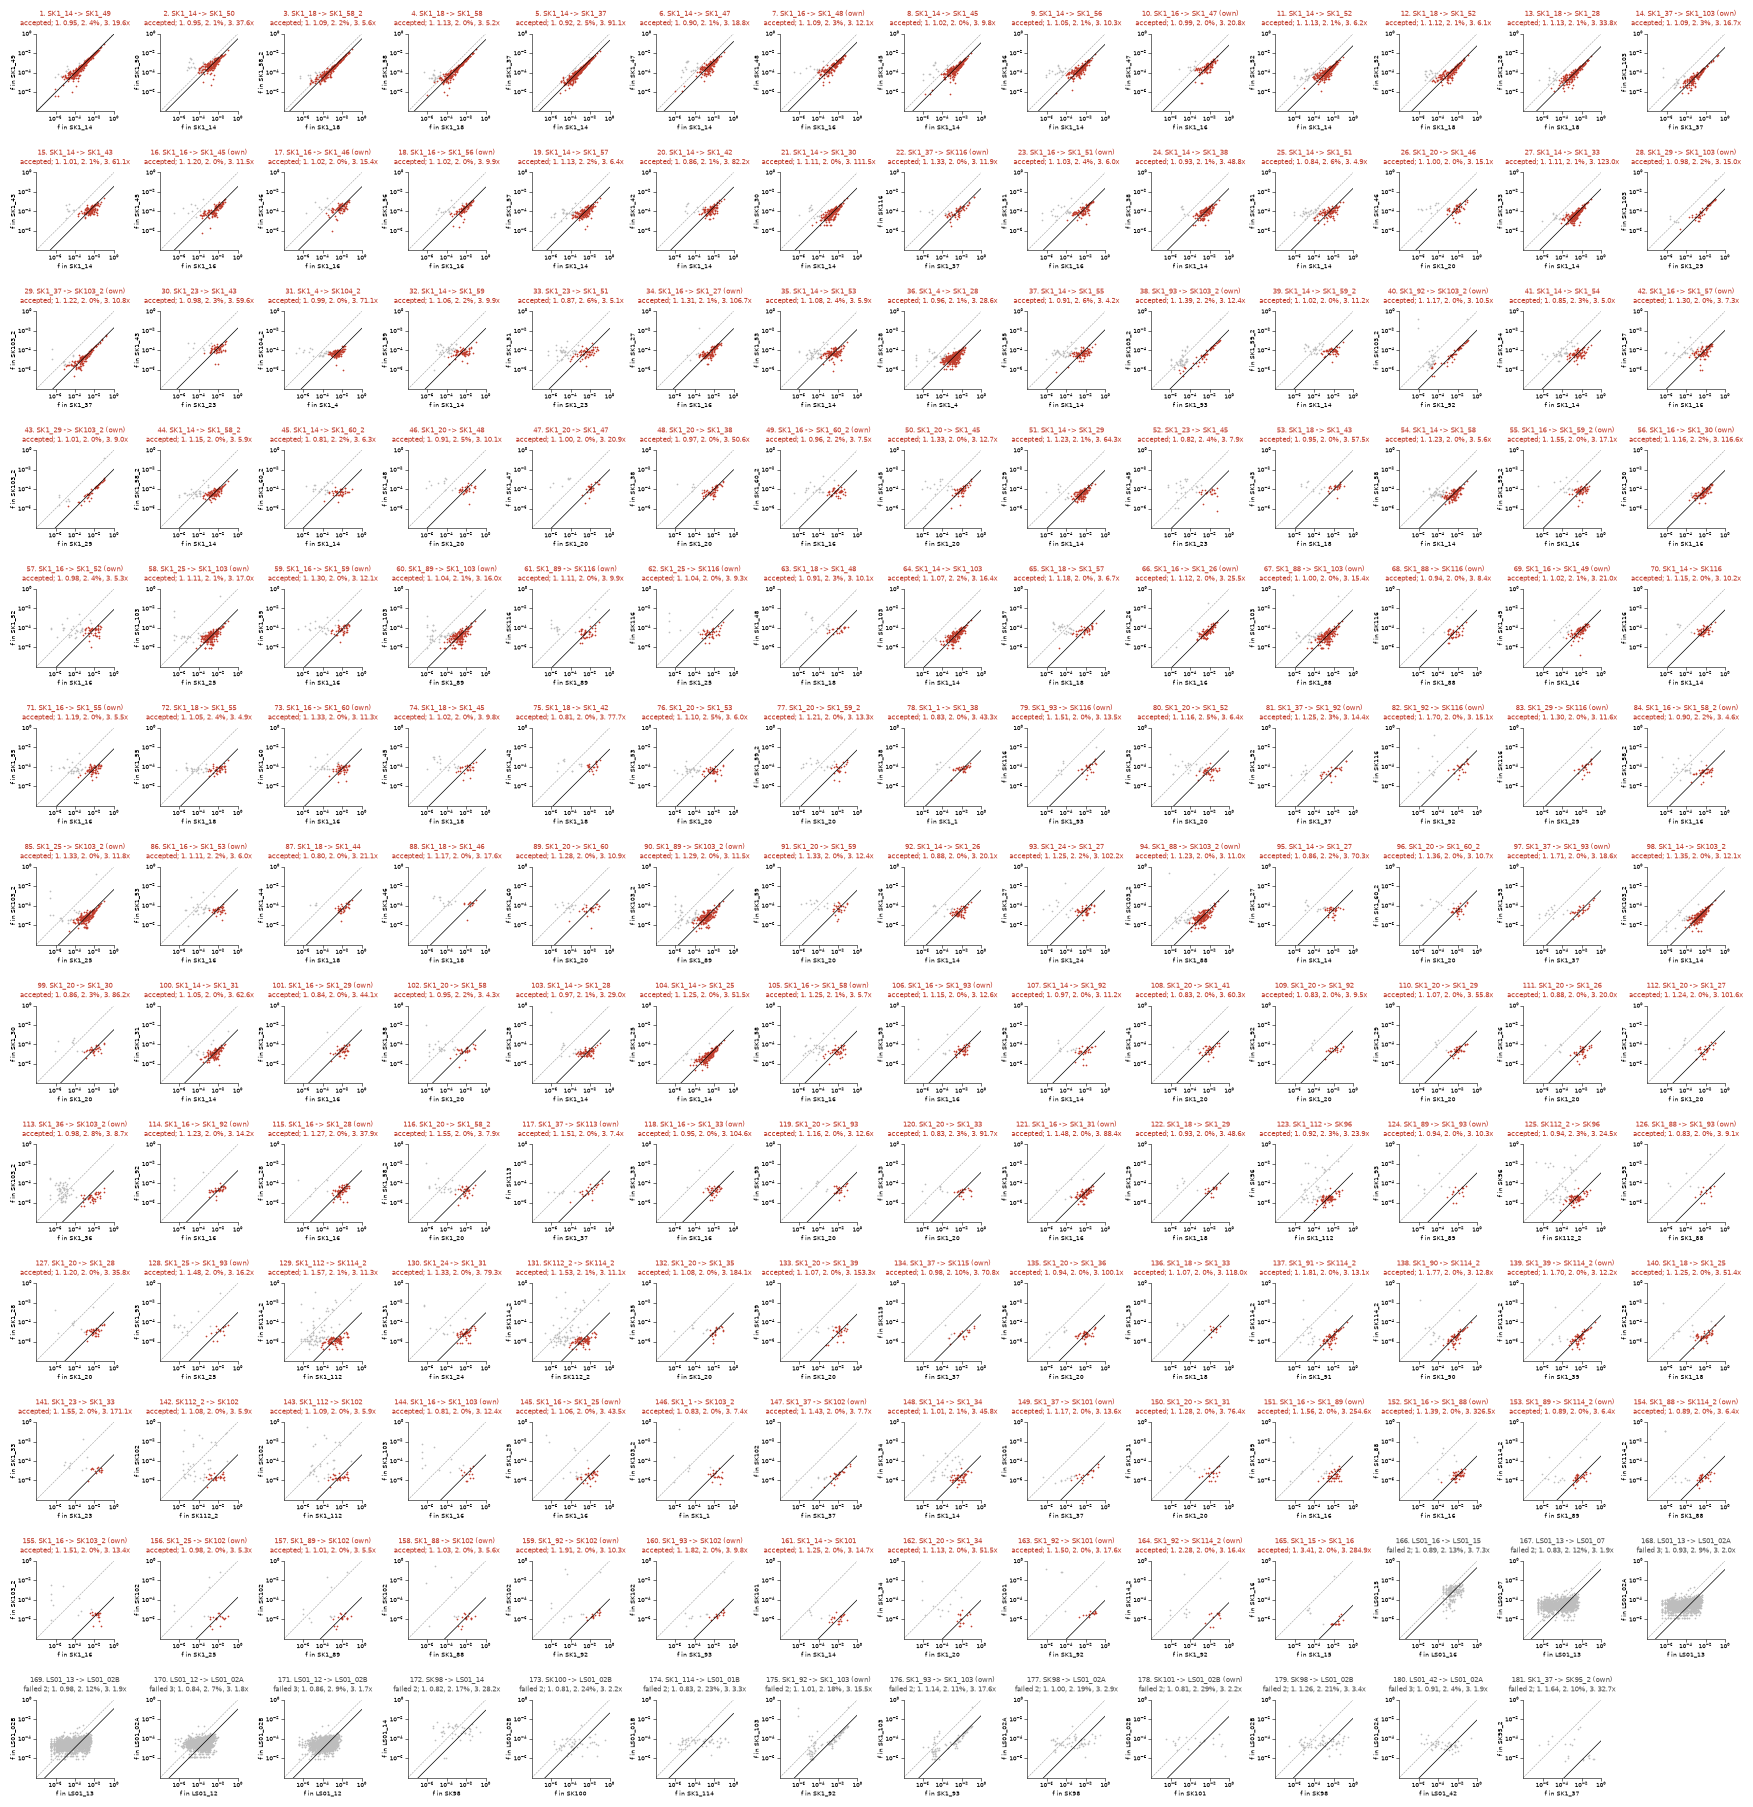

{'accepted': 165, 'failed 2': 12, 'failed 3': 4}


In [23]:
name = 'cotravel_all_check_1'
si = 'si'

# every pair that passes check 1 (impossible exp. 2 -> exp. 1 pairs left out), accepted first
show = cotravel[cotravel.check_1 & ~cotravel.impossible].copy()
show['verdict'] = np.select([show.accepted, ~show.check_2], ['accepted', 'failed 2'], 'failed 3')
show = show.sort_values(['accepted', 'slope'], ascending=[False, False])

lims = [1e-8, 1]; ticks = [1e-6, 1e-4, 1e-2, 1]   # same on x and y
nc = int(np.ceil(np.sqrt(len(show)))); nr = int(np.ceil(len(show) / nc))   # square grid: 14 x 13 for 181 pairs
fig, axes = plt.subplots(nr, nc, figsize=(1.25 * nc, 1.4 * nr))
for ax in axes.flat: ax.axis('off')
show['panel'] = np.arange(1, len(show) + 1)
for ax, (_, row) in zip(axes.flat, show.iterrows()):
    ax.axis('on'); p = pair__stats[(row.source, row.recipient)]
    rem = explained(p) if row.accepted else np.zeros(len(p['common']), bool)   # red = removed from the recipient
    ax.scatter(p['fs'][~rem], p['fr'][~rem], s=1.5, color='#bdbdbd', linewidth=0, rasterized=True)
    ax.scatter(p['fs'][rem], p['fr'][rem], s=1.5, color='#c13e2e', linewidth=0, rasterized=True)
    ax.plot(lims, lims, color='#9e9e9e', linewidth=0.4, linestyle='--', zorder=0)                       # 1:1
    ax.plot(lims, [row.slope * lims[0], row.slope * lims[1]], color='black', linewidth=0.5)            # the fitted line (dose)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lims); ax.set_ylim(lims); ax.minorticks_off()
    ax.set_xticks(ticks); ax.set_yticks(ticks); ax.tick_params(labelsize=4, length=2, width=0.4, pad=1)
    ax.set_box_aspect(1)   # square
    ax.set_xlabel(f'f in {row.source}', size=4.5, labelpad=1); ax.set_ylabel(f'f in {row.recipient}', size=4.5, labelpad=1)
    ax.spines[['top', 'right']].set_visible(False); ax.spines[['bottom', 'left']].set_linewidth(0.4)
    c = '#c13e2e' if row.accepted else '#555555'
    ax.set_title(f"{row.panel}. {row.source} -> {row.recipient}{' (own)' if row.own_only else ''}\n{row.verdict}; 1. {row.found:.2f}, 2. {100 * row.below:.0f}%, 3. {row.specific:.1f}x", size=5, color=c)

    # numbers reported in figs:
    # 1. of the source’s clones expected in the recipient at the fitted dose, this fraction is actually there (passes at >= 0.8)?
    # 2. contamination shows up in the recipient at the same small fraction or more, never less; 
    #    if many shared barcodes have clearly less than that fraction (set at 10%)
    # 3. how many times higher this source is found is than the median found of all other sources into the same recipient?
    #    passes at ≥ 3x; nan means the recipient had no other source to compare with, so it passes
    
plt.tight_layout(); plt.savefig(path_to_save_figs + si + '_' + name + '.pdf', dpi=300, bbox_inches='tight'); plt.show()

print(show.verdict.value_counts().to_dict())
#show[['panel', 'source', 'recipient', 'verdict', 'own_only', 'slope', 'found', 'below', 'specific']].to_csv('./cotravel_review_panels.tsv', sep='\t', index=False)

In [24]:
# 7160c2 (AAGG) is left out of the exp. 1 in vivo samples: it contaminated most of them at library prep (see the note above); exp. 2 is clean
exp__excluded_clIDs = {'1': ['AAGG']}
excluded = pd.Series([c in exp__excluded_clIDs.get(e, []) for c, e in zip(barcode_reads.clID, barcode_reads.exp)], index=barcode_reads.index)
barcode_reads['7160c2'] = excluded & barcode_reads['sample'].isin(in_vivo)

In [25]:
# rule 4: barcodes found in more day-2 mice than the injection allows (small contamination that recurs but is too weak for rule 3)
# a barcode is seen in a day-2 library with probability 1 - exp(-lambda), 
# lambda = expected molecules = (molecules of its cell line in that library) x (its share of that line in the pool; 
# a pool-absent barcode counts as one molecule)
# flag if P(seen in >= as many mice as observed) < MANY_MICE_ALPHA

def many_mice_flags(alpha=MANY_MICE_ALPHA):
    kept = ~barcode_reads[['SPIKE', 'DAY2', 'COTRAVEL', '7160c2']].any(axis=1)
    flags = pd.Series(False, index=barcode_reads.index); tests = []
    for e in exp__pre_injection_samples:
        L = [s for s in day2 if metadata.loc[s, 'experiment'] == e]
        sub = barcode_reads[kept & barcode_reads['sample'].isin(L)]
        X = sub.pivot_table(index='key', columns='sample', values='reads', aggfunc='sum').reindex(columns=L).fillna(0) # reads of each kept barcode in each day-2 library
        line = X.index.str[:4]

        pool = key_exp__pre_injection_reads[e] / R_POOL # pool molecules per barcode
        k = pool.reindex(X.index).fillna(0).values
        line_pool = pool.groupby(pool.index.str[:4]).sum().reindex(line).fillna(0).values
        w = (k + 1) / (line_pool + 1) # barcode's share of its line in the pool

        mol = X / calibration.loc[L, 'reads_per_template'].values # molecules in each library
        line_mol = mol.groupby(line).transform('sum').values # molecules of the barcode's line in each library
        p_lib = 1 - np.exp(-w[:, None] * line_mol) # chance of seeing the barcode in each library

        mice = sorted(set(sample__mouse[s] for s in L))
        cols = [[i for i, s in enumerate(L) if sample__mouse[s] == m] for m in mice]
        p_m = np.column_stack([1 - np.prod(1 - p_lib[:, c], axis=1) for c in cols]) # chance per mouse
        k_m = np.column_stack([(X.values[:, c] > 0).any(axis=1) for c in cols]).sum(axis=1) # mice that have it

        # P(seen in >= k_m mice), each mouse with its own chance (Poisson-binomial, built up one mouse at a time)
        pk = np.zeros((len(X), len(mice) + 1)); pk[:, 0] = 1
        for j in range(len(mice)):
            pj = p_m[:, [j]]; nxt = pk * (1 - pj); nxt[:, 1:] += pk[:, :-1] * pj; pk = nxt
        p = np.take_along_axis(np.cumsum(pk[:, ::-1], axis=1)[:, ::-1], k_m[:, None], axis=1)[:, 0]

        flags |= kept & barcode_reads['sample'].isin(L) & barcode_reads.key.isin(X.index[p < alpha])
        tests.append(pd.DataFrame({'exp': e, 'key': X.index, 'mice': k_m, 'of_mice': len(mice), 'expected_mice': p_m.sum(axis=1), 'p': p}))
    return flags, pd.concat(tests, ignore_index=True)

barcode_reads['MANY_MICE'], many_mice = many_mice_flags()
hits = many_mice[many_mice.p < MANY_MICE_ALPHA]
print(f'{len(hits)} barcodes in too many day-2 mice ({hits.groupby("exp").size().to_dict()}); {int(barcode_reads.MANY_MICE.sum())} sample-barcode pairs flagged')
hits.sort_values('p').head(20).round(3)

18 barcodes in too many day-2 mice ({'1': 18}); 202 sample-barcode pairs flagged


,exp,key,mice,of_mice,expected_mice,p
143872,1,GTTG_TTGGCAGGACAGGGGG,13,13,0.452,0.0
138528,1,GTTG_ACCGAGGGCCGGTTGG,13,13,0.452,0.0
148614,1,TTCC_ACAGGAAGTTAGAAAG,11,13,0.198,0.0
48174,1,CAAC_ATTGGTCGTGAGTCTG,13,13,1.021,0.0
142249,1,GTTG_GTTGTTGGTACGGGAG,11,13,0.452,0.0
154580,1,TTGG_AAGGTACGGGCGGGAG,10,13,0.358,0.0
113256,1,GCAT_GACGAGTGTAGGAAGG,9,13,0.262,0.0
64499,1,CAGA_TGTGCTAGCCTGTGTG,10,13,0.535,0.0
109397,1,CTTC_TTGGTTGGCTGGCGAG,8,13,0.266,0.0
109281,1,CTTC_TGTGTATGTTGGGATG,8,13,0.266,0.0


In [26]:
# all rules together
rules = ['SPIKE', 'DAY2', 'COTRAVEL', 'MANY_MICE', '7160c2']
barcode_reads['flagged'] = barcode_reads[rules].any(axis=1)
iv = barcode_reads['sample'].isin(in_vivo)
iv_total = barcode_reads.loc[iv, 'reads'].sum()
summary = pd.DataFrame({r: {'pairs': int((iv & barcode_reads[r]).sum()),
                            'read fraction': round(barcode_reads.loc[iv & barcode_reads[r], 'reads'].sum() / iv_total, 4),
                            'samples': barcode_reads.loc[iv & barcode_reads[r], 'sample'].nunique()} for r in rules + ['flagged']}).T
display(summary)

# one table with every removed sample-barcode pair, the rule(s) that removed it and, for rule 3, its source(s)
cols = ['sample', 'mouse', 'exp', 'clID', 'barcode', 'reads', 'frac'] + rules + ['cotravel_source']
barcode_reads.loc[iv & barcode_reads.flagged, cols].to_csv(path_to_data + 'flagged_barcodes.tsv', sep='\t', index=False) # SAVING OUT

# cleaned counts: one file per sample, same format as bc-counts-clustered/, flagged pairs dropped
# (spike-in barcodes are never flagged; in vitro, pre-injection and LA67 files are copied unchanged)
sample__drop = barcode_reads[iv & barcode_reads.flagged].groupby('sample').key.apply(set).to_dict()
removed = {}
for f in sorted(os.listdir(path_to_reads)):
    s = f.replace('_clIDs_rBC_cluster_counts.txt', '')
    df = pd.read_csv(path_to_reads + f, sep='\t', header=None, names=['key', 'reads'], dtype={'key': str, 'reads': int})
    drop = df.key.isin(sample__drop.get(s, set()))
    removed[s] = {'barcodes_removed': int(drop.sum()), 'reads_removed': int(df.loc[drop, 'reads'].sum()), 'reads_total': int(df.reads.sum())}
    # SAVING FINAL READ COUNTS POST-CLUSTERING AND CLEAN-UP
    df[~drop].to_csv(path_to_cleaned + f.replace('.txt', '_cleaned.txt'), sep='\t', header=False, index=False)

removed = pd.DataFrame(removed).T; removed['read_fraction_removed'] = removed.reads_removed / removed.reads_total
print(f'{len(removed)} files written; {int(removed.barcodes_removed.sum()):,} sample-barcode pairs removed, {100 * removed.reads_removed.sum() / removed.reads_total.sum():.2f}% of all reads')

,pairs,read fraction,samples
SPIKE,1285.0,0.0201,99.0
DAY2,704.0,0.0336,19.0
COTRAVEL,10566.0,0.0245,52.0
MANY_MICE,202.0,0.0002,19.0
7160c2,16547.0,0.0135,99.0
flagged,28293.0,0.0582,99.0


191 files written; 28,293 sample-barcode pairs removed, 5.13% of all reads


In [27]:
# SAVING READ AND CELL COUNTS TABLES
# note that the contaminating cell line was removed from exp 1 – need to be careful downstream

# per-cell-line tables used by the figures, rebuilt from the cleaned counts
# read counts: reads summed per clID, every sample (GATC row = spike-in reads)
# cell counts: in vivo samples with spike-in, merged as in the 'notes' column; cells = reads x N / (1 + spike-in reads), N = SPIKEIN_CELLS
#   (libraries with one spike-in: reads added up first; separate spike-ins: each library converted, then added up)
read_counts = pd.DataFrame(0, index=pd.Index(clIDs, name='clID'), columns=metadata.index)
for s in metadata.index:
    df = pd.read_csv(path_to_cleaned + f'{s}_clIDs_rBC_cluster_counts_cleaned.txt', sep='\t', header=None, names=['key', 'reads'])
    read_counts[s] = df.groupby(df.key.str[:4]).reads.sum().reindex(clIDs).fillna(0).astype(int).values

merged = [] # merged sample names, in metadata order
for s in metadata.index:
    if metadata.loc[s, 'experiment'] not in ('1', '2') or metadata.loc[s, 'time point, d'] == 0 or not metadata.loc[s, 'spike-in added']: continue
    note = str(metadata.loc[s, 'notes'])
    m = note.split()[0] if ':' in note else s
    if m not in merged: merged.append(m)

cell_counts = pd.DataFrame(0.0, index=pd.Index(clIDs, name='clID'), columns=merged)
for m in merged:
    subs = m.split(':'); N = SPIKEIN_CELLS[metadata.loc[subs[0], 'experiment']]
    if len(subs) > 1 and 'separate' in str(metadata.loc[subs[0], 'notes']):
        cell_counts[m] = sum(N / (1 + read_counts.loc['GATC', s]) * read_counts[s] for s in subs)
    else:
        reads = read_counts[subs].sum(axis=1)
        cell_counts[m] = N / (1 + reads['GATC']) * reads

read_counts.to_csv(path_to_data + 'cell-line_read_counts.csv')
cell_counts.to_csv(path_to_data + 'cell-line_cell_counts.csv')
print(f'read counts: {read_counts.shape[1]} samples; cell counts: {cell_counts.shape[1]} (merged) samples')

read counts: 191 samples; cell counts: 119 (merged) samples
